In [140]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.linear_model import LinearRegression

# Decisions log

Decisions made during exploratory analysis. Data-cleaning changes are applied in
`combining.ipynb`; modeling decisions are applied in the modeling notebook.

## Pending changes to `combining.ipynb`

- [ ] **Diastolic BP:** treat single readings below 40 mm Hg (including recorded zeros) as
  missing before averaging. Affects 13 participants whose mean DBP was below 40 (minimum 12).
  Low values are consistent with auscultatory artifacts; replaces the zero-only rule.
- [ ] *(Optional)* **Survey weights:** carry `WTDRD1` and `WTDR2D` into the person table for
  weighted descriptive statistics.
- [ ] *(Optional)* **Height:** carry `BMXHT` into the person table and compute
  `WHTR = BMXWAIST / BMXHT`, if waist-to-height ratio is chosen as the body-size outcome.

## Open questions

- [ ] Body-size outcome: waist or waist-to-height ratio (decide before modeling, on measurement grounds).
- [ ] Healthy-cluster rule: precise test for "lower than average" (negative adjusted difference in
  training and test folds, or 95% CI excluding zero in held-out data).
- [ ] How correlated candidates are handled during selection (e.g., stability selection; a VIF
  constraint on the selected set).
- [ ] Citations for each row of the expert heuristic set.
- [ ] Rerun PCA on the final 83-feature pool and update the PCA entry.

---

## Outcomes (fixed before modeling)

- **Primary:** HbA1c (continuous).
- **Secondary:** body size (waist or waist-to-height ratio; see open questions), CRP (log),
  HDL (log), total cholesterol, systolic and diastolic BP. BMI is reported but treated as
  redundant with waist (Spearman 0.90).
- All outcomes are reported regardless of results.
- **Healthy-cluster rule:** based on adjusted HbA1c; if no cluster differs from the overall mean
  on held-out data, body size is used instead, as decided in advance.

### Outcome transformations

| Outcome | Skew (raw → log) | Decision |
|---|---|---|
| CRP | 6.90 → 0.33 | Log |
| HDL | 1.33 → 0.16 | Log |
| BMI | 1.16 → 0.33 | Log |
| Waist | 0.55 → 0.07 | Raw |
| HbA1c | 4.61 → 2.25 | Raw (skew driven by a few extreme values; log does not fix it) |
| Total cholesterol, SBP, DBP | — | Raw |

### Outcome-specific handling

- **HbA1c:** 117 participants (3.6%) are in the diabetes range (≥ 6.5) without a diagnosis;
  16 (0.5%) are at ≥ 9. Keep all in the main analysis. Stratify CV folds by HbA1c group and report
  MAE alongside RMSE.
- **CRP:** 223 participants (6.9%) have CRP > 10 mg/L, likely acute inflammation. Exclude them
  from CRP models in the main analysis.
- **Correlations among outcomes:** BMI, waist and CRP form a body-size/inflammation cluster
  (HDL inversely). HbA1c is only weakly correlated with the other outcomes (≤ 0.31); its strongest
  link, with systolic BP, likely reflects their shared association with age. Results within the
  body-size cluster are not independent confirmations.
- **Waist and sex:** waist differs by sex (and height). Sex is a control in every model;
  waist-to-height ratio is an alternative that removes body size directly.

## Controls

- **Missing data:** income missing for 388 (11.8%) → missing indicator. Other controls
  (food security, activity, sedentary time, education; ≤ 4.2% missing) → simple imputation.
  All imputation fitted inside CV training folds.
- **Physical activity:** use `log1p(MET_MIN_WK)` or `MEETS_PA`; raw MET-minutes are highly
  skewed (mean 4,125, median 1,440).
- **Collinearity:** low. Adjusted GVIFs range from 1.04 to 1.26. Income, education and food
  security are moderately related (Cramér's V ≈ 0.33) and should be interpreted together.
- **Reference levels:** use large, typical groups as references in one-hot encoding.

## Diet feature preprocessing

- All diet features per 1,000 kcal (`_P1K`), with total energy (`KCAL`) as a shared covariate
  in every model. Per-1,000-kcal features measure diet density/composition; coefficients for
  energy-providing features are substitution effects.
- `log1p`, then standardize. Scaling parameters fitted inside CV training folds.
- Residual skew in food groups and flavonoids comes from structural zeros (24-hour recall),
  not the transform.
- **Limitation:** zero intake on recall days ≠ never consumed; episodically eaten foods
  (fish, legumes, yogurt, dark greens) are under-captured.
- **Crowding out:** added sugars and solid fats correlate negatively with fiber, potassium and
  magnesium per 1,000 kcal (ρ ≈ −0.4) but not in absolute terms (ρ ≈ −0.03 to +0.21), consistent
  with displacement within a fixed energy budget.

## Feature sets compared

All models include the same demographic/lifestyle controls and `KCAL`, and use identical
preprocessing. The three diet sets each have 13 features.

| Set | Contents |
|---|---|
| **Baseline** | Controls only |
| **Label** | The 13 FDA Nutrition Facts nutrients available in FNDDS, exactly as listed: total fat, saturated fat, cholesterol, sodium, total carbohydrate, fiber, total sugars, added sugars, protein, vitamin D, calcium, iron, potassium. Trans fat is not available in FNDDS 2017–2018. Calories enter as the shared `KCAL` covariate. |
| **Expert heuristic** | 13 features chosen from the literature (below) |
| **Selected** | 13 features chosen by a data-driven method from the 83-feature candidate pool |

- **Slot definition:** each line is a pre-defined, nameable quantity (an individual nutrient, or an
  existing USDA food or flavonoid category with its standard definition). No investigator-built or
  outcome-weighted composites.
- **Label model** uses the label nutrients exactly as listed, with no drops or re-expressions.
  - High multicollinearity among label nutrients complicates interpretation of individual
    label-model coefficients but does not affect predictive performance, the basis of comparison.
  - The label's redundancy is inherent: per-serving calories are approximately determined by the
    listed macronutrients, and several lines are nested (saturated within total fat; fiber and
    sugars within carbohydrate). Our person-level representation preserves this structure rather
    than introducing it.
- **Scale:** the label is defined per serving; at the person level it is represented as density
  (per 1,000 kcal) plus energy.

## Label redundancy (outcome-free)

TODO


## Evaluation design

- **Nested cross-validation** for performance: outer folds score each approach on unseen data;
  inner folds handle tuning and feature selection. Folds stratified by HbA1c group. Models are
  compared fold by fold (paired).
- **Final models** for interpretation (and the app) are refit on all data using the same procedure.
- Everything learned from data (imputation, scaling, selection, tuning) happens inside the folds.
- The reported performance describes the whole procedure (selection + tuning + fitting), not a
  single fitted model.
- **Model types:** linear/lasso (and ridge), KNN.
- **Nonlinearity:** many nutrients plausibly have U/J-shaped associations. Linear selection detects
  monotone signals only (limitation).
- **Interpretation:** coefficients are read only for the selected (and heuristic) sets, as
  associations. Statements in food units come from model predictions, not raw coefficients.
  VIF is rechecked on the final selected set before interpretation.
- **Sensitivity analyses:** TODO

## Notes for the write-up

- Age is the dominant demographic difference between HbA1c groups (60+: 50% of elevated vs 25%
  of normal), followed by race/ethnicity and physical activity.
- NHANES oversamples Hispanic, Black and Asian participants; unweighted results describe the
  sample, not the U.S. population.
- Blood pressure shows terminal digit preference (spikes at round values).
- 3.6% of adults without a diabetes diagnosis had HbA1c in the diabetes range.
- **Discussion angle:** a food-based heuristic label may be more robust to "nutritionism" and
  reformulation (Goodhart's law) than a nutrient-based one. Supported indirectly by the fortification
  nutrient block and by nutrient-vs-food preferences in selection; not directly testable here.
- **Possible extension:** independent validation on NHANES 2015–2016.

---

## Candidate feature pool for selection

All features are per 1,000 kcal (`_P1K`). **Pool decisions use structural criteria only**
(definitions, correlation, sparsity), never biological importance. Literature informs only the
expert heuristic set, so that the data-driven selected set is not filtered toward known results.

**Why prune before selection:** without it, selection could return near-duplicate, unreadable
components (e.g., individual theaflavins or saturated fatty acids). Relabeling them into categories
afterwards would mean the reported label no longer matches the fitted model, and near-copies would
split selection frequency. Pruning beforehand, using predictor-only rules, makes the selected
features directly usable as label lines and prevents signal dispersion.

Features relate to each other in five ways, each with its own rule:

| Relationship | Definition | Example | Rule |
|---|---|---|---|
| **Part–whole** | Aggregate is the exact sum of its components | Total fat = SFA + MUFA + PUFA; vitamin A = retinol + carotenoids; FPED totals | If mean between-component ρ > 0.6, keep the aggregate; otherwise keep the components and drop the aggregate |
| **Duplicate** | Same quantity recorded twice (ρ ≈ 1) | Legumes as vegetable vs protein; ALCO vs A_DRINKS | Keep one |
| **Overlapping measurement** | Different quantities from shared foods; neither is a sum of the other | Lycopene vs tomatoes; SFAT vs solid fats | Keep both; selection decides |
| **Energy identity** | Calories are fixed by the macronutrients (4 kcal/g carbohydrate and protein, 9 fat, 7 alcohol), so per 1,000 kcal one is determined by the others | Carbohydrate vs protein, fat, alcohol | Drop carbohydrate, an aggregate of sugars + fiber + starch whose sugars and fiber are kept; selected macronutrients read as "instead of starch" |
| **Chemical class** | Components of one biochemical class from a shared source, jointly redundant | EPA, DPA, DHA (long-chain n-3; DHA VIF 20.2, mean pairwise ρ 0.59) | Sum into the class total (`LC_N3`), as with flavonoid classes. ALA (short-chain n-3, plant source) kept separate |

### 1. Part–whole groups

The 0.6 threshold is the largest gap in the observed distribution of mean between-component
Spearman correlations (0.67 vs 0.45). Above it, components are near-duplicates.

| Group | Mean ρ | Keep | Drop |
|---|---|---|---|
| Isoflavones | 0.80 | Class total | 3 compounds |
| Saturated fatty acids | 0.71 | SFAT | S040–S180 |
| Anthocyanidins | 0.70 | Class total | 6 compounds |
| Flavan-3-ols | 0.69 | Class total | 11 compounds |
| Flavanones | 0.67 | Class total | 3 compounds |
| Flavonols | 0.45 | Quercetin, kaempferol, myricetin, isorhamnetin | Class total |
| Flavones | 0.42 | Apigenin, luteolin | Class total |
| Monounsaturated FAs | 0.38 | M161, M181, M201, M221 | MFAT |
| Polyunsaturated FAs | 0.30 | P182, P183 (ALA), P184, P204, `LC_N3` = P205 + P225 + P226 (chemical-class rule) | PFAT; P205, P225, P226 individually |
| Vitamin A | 0.21 | Retinol, β-carotene, α-carotene, β-cryptoxanthin | VARA |
| Fruit | 0.18 | Citrus/melons/berries, other fruit, juice | F_TOTAL |
| Vegetables | 0.11 | Subgroups | V_TOTAL, V_REDOR_TOTAL, V_STARCHY_TOTAL |
| Dairy | −0.02 | Milk, yogurt, cheese | D_TOTAL |
| Meat/poultry/seafood | −0.02 | Subgroups (except organ meat) | PF_MPS_TOTAL, PF_TOTAL |
| Folate | −0.13 | FF (food folate), FA (folic acid) | FOLA, FDFE |
| Grains | −0.24 | Whole, refined | G_TOTAL |

Also under this rule:
- **Total fat (TFAT):** exact sum of SFA, MUFA and PUFA (+ minor fats); components kept.
- **Total flavonoids:** sum of all classes; dropped.

### 2. Duplicates

- **Legumes:** V_LEGUMES and PF_LEGUMES record the same intake in different units
  (ρ = 1.00; PF = 4 × V). Kept once as `LEGUMES` = V_LEGUMES (cup-equivalents).
- **Alcohol:** ALCO dropped; A_DRINKS kept (ρ = 1.00).

### 3. Overlapping measurements (kept)

The strongest cross-group correlations link a nutrient with its main food source (e.g.,
SFAT–solid fats 0.89, lycopene–tomatoes 0.85, α-carotene–orange vegetables 0.72,
cholesterol–eggs 0.72, lutein and vitamin K–dark greens ≈ 0.66). None reach duplicate level,
so all are retained. Selection results will be examined for whether foods or their marker
nutrients are preferred.

### 4. Energy identity

Carbohydrate is removed. Starch, the remaining part of carbohydrate, has no separate feature, so
the identity is broken. The label model still includes total carbohydrate, since it represents
the FDA label as is. As a consequence, the selected label cannot contain total carbohydrate or
total fat; calories plus the remaining lines still determine them.

### 5. Chemical class

EPA, DPA and DHA are summed into long-chain omega-3s (`LC_N3`). The heuristic set separately uses
`OMEGA3` (EPA + DHA), following the literature; this is allowed there and not part of the pool.

### Other

- **Sparsity:** features with more than 95% zero values are dropped. Only organ meat
  (PF_ORGAN, 98% zero) is affected.
- **Kept, with note:** MOIS (water per 1,000 kcal, the inverse of energy density).

**Result:** 83 candidate features (46 nutrients, 27 food groups, 10 flavonoid features), down from 138.

### Notes

- **Remaining correlations** reflect real dietary patterns (plant foods, dairy + fortified cereal,
  animal protein, fats, added sugars) and are kept.
- **VIF (83-feature pool, refit version with sugars split):** after removing carbohydrate and
  collapsing EPA, DPA and DHA (DHA VIF 20.2 → `LC_N3` 6.6), only protein (13.5) and choline (10.7)
  exceed 10. Both reflect overlapping measurements of animal-protein foods and are retained.
  The pool is not VIF-filtered.
- **Interpretable refit** (modeling notebook only): sugars re-expressed as added + natural
  (SUGR − 4.2 × ADD_SUGARS). VIF rechecked on the final selected set.
- **Data leakage.** These decisions were made on the full cohort before cross-validation, so
  test-fold *predictor* values technically informed the feature pool, a mild form of unsupervised
  leakage. No outcome information was used, most decisions are definitional (exact sums, duplicate
  units, the energy identity, chemical classes), and the data-driven ones (the >95% sparsity cutoff;
  the 0.6 collapse threshold at the gap between 0.67 and 0.45) are extreme enough that they are
  unlikely to change across folds. We expect negligible effect on performance estimates; this can be
  confirmed by recomputing them within training folds. Everything learned from data in modeling
  happens inside the folds.
- **Limitations of the pruning:** the 0.6 threshold was chosen after seeing the distribution; group
  averages can miss tight subclusters within loose groups; decisions were refined iteratively with
  the full data in view.

---

## Expert heuristic set (fixed before any outcome analysis)

A simplified heuristic model: 13 features chosen from the nutrition literature, not from this
dataset. Mostly foods, reflecting where the evidence for diabetes and cardiometabolic risk is
strongest, plus nutrients and compounds with established roles (fiber, added sugars, omega-3,
anthocyanins).

| # | Feature | Rationale |
|---|---|---|
| 1 | FIBE | Fiber: slows glucose absorption; lower diabetes risk |
| 2 | G_WHOLE | Whole grains: lower diabetes risk |
| 3 | G_REFINED | Refined grains: high glycemic load |
| 4 | ADD_SUGARS | Added sugars: glycemic load, weight gain |
| 5 | F_WHOLE = F_CITMLB + F_OTHER | Whole fruit: lower risk |
| 6 | V_DRKGR | Green leafy vegetables: lower risk |
| 7 | LEGUMES | Legumes: fiber, low glycemic index |
| 8 | PF_NUTSDS | Nuts and seeds: unsaturated fats, insulin sensitivity |
| 9 | PF_MEAT | Red meat: higher risk |
| 10 | PF_CUREDMEAT | Processed meat: higher risk |
| 11 | D_YOGURT | Yogurt: lower risk |
| 12 | OMEGA3 | Marine omega-3s (EPA + DHA) |
| 13 | FL_TOT_ANTHOCYAN | Anthocyanins (berries): lower diabetes risk |

Considered and excluded: magnesium (overlaps plant foods), caffeine (imperfect coffee marker),
fruit juice (lower priority given 13 slots; whole fruit and added sugars judged more central).
Sources: [add meta-analysis citations per row].

---

## HbA1c descriptive (diet vs HbA1c, descriptive only)

All single-feature associations are weak (|ρ| ≤ 0.14 raw, ≤ 0.11 adjusted for age and sex).
Alcohol (−), caffeine (−) and refined grains (+) are the strongest after adjustment. Fiber shows a
positive association, likely reverse causation (dietary change after risk awareness). Adjustment
changes several associations substantially, indicating age confounding. Run after the heuristic set
was fixed; no modeling decisions were changed based on these results.

## PCA on diets

PCA preview (83-feature pool, log1p, standardized; outcome-free).
- PC1 (14.7%): plant-rich vs added sugars and solid fats (diet quality).
- PC2 (8.5%): animal-source foods vs plant foods and tea.
- PC3 (6.5%): oils and fats vs fortified cereal and milk.
- PC4 (4.6%): seafood (long-chain omega-3s) vs added fats.

First four ≈ 34% of variance; no dominant pattern. Patterns match the earlier 79-feature run
(PC1–PC3 unchanged), so they do not depend on pruning details.

## Under consideration (not yet decided)

- **Nonlinearity:** compare a flexible model (random forest or KNN) with lasso on the same feature
  sets; partial dependence plots; optional spline refit for interpretation.
- **Scale sensitivity:** evaluate all feature sets on the absolute daily scale as well as per 1,000 kcal.
- **HbA1c tail:** rerun the main comparison without the 16 participants at ≥ 9.
- **CRP:** include CRP > 10 mg/L (with log CRP) as a sensitivity check.
- **Pruning check:** run selection on the full 138-feature set to test whether pruning affects results.
- **Label redundancy:** effective-dimension comparison of the label against random 13-feature sets;
  hypothesis that a less redundant set predicts better; redundancy vs content explanations.

In [141]:
df = pd.read_csv("data/processed/analytic_cohort.csv")

In [142]:
print(df.shape)

(3286, 305)


In [143]:
# Construct mapping to translate numbers to underlying values
cat_vars = {
    "RIAGENDR": ("Sex", {1: "Male", 2: "Female"}),
    "AGE_GROUP": ("Age group", None),
    "RIDRETH3": ("Race/ethnicity", {1: "Mexican American", 2: "Other Hispanic", 3: "Non-Hispanic White",
                                    4: "Non-Hispanic Black", 6: "Non-Hispanic Asian", 7: "Other/multiracial"}),
    "DMDEDUC2": ("Education", {1: "Less than 9th grade", 2: "9th-11th grade", 3: "High school/GED",
                               4: "Some college/AA", 5: "College graduate+"}),
    "SMOKING": ("Smoking", {"never": "Never", "former": "Former", "current": "Current"}),
    "MEETS_PA": ("Meets activity guideline", {0: "No", 1: "Yes"}),
    "FSDHH": ("Household food security", {1: "Full", 2: "Marginal", 3: "Low", 4: "Very low"}),
    "N_DAYS": ("Recall days", {1: "1 day", 2: "2 days"}),
}

# Bin by age group
df["AGE_GROUP"] = pd.cut(df["RIDAGEYR"], bins=[20, 40, 60, 81], right=False,
                         labels=["20-39", "40-59", "60+"])

# Create 
rows = []

# Fix a column
for col, (name, mapping) in cat_vars.items():
    # Either use above mapping or take as is
    s = df[col].map(mapping) if mapping else df[col].astype("object")

    # Retrieve unique levels, order them 
    order = list(mapping.values()) if mapping else list(s.cat.categories if hasattr(s, "cat") else s.dropna().unique())
    counts = s.value_counts().reindex(order, fill_value=0)

    # Count missing
    n_missing = s.isna().sum()

    # If missing
    if n_missing:
        counts["Missing"] = n_missing

    # Output levels
    for level, n in counts.items():
        rows.append({"Variable": name, "Level": level, "n": n, "%": round(100 * n / len(df), 1)})

table1_cat = pd.DataFrame(rows)
print(table1_cat.to_string(index=False))

                Variable               Level    n    %
                     Sex                Male 1503 45.7
                     Sex              Female 1783 54.3
               Age group                 60+ 1101 33.5
               Age group               40-59 1099 33.4
               Age group               20-39 1086 33.0
          Race/ethnicity    Mexican American  420 12.8
          Race/ethnicity      Other Hispanic  309  9.4
          Race/ethnicity  Non-Hispanic White 1207 36.7
          Race/ethnicity  Non-Hispanic Black  737 22.4
          Race/ethnicity  Non-Hispanic Asian  458 13.9
          Race/ethnicity   Other/multiracial  155  4.7
               Education Less than 9th grade  220  6.7
               Education      9th-11th grade  344 10.5
               Education     High school/GED  779 23.7
               Education     Some college/AA 1088 33.1
               Education   College graduate+  850 25.9
               Education             Missing    5  0.2
          

/var/folders/wn/4vhmdq557_7f8325xdqxk2tr0000gn/T/ipykernel_70590/1596359198.py:16: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["AGE_GROUP"] = pd.cut(df["RIDAGEYR"], bins=[20, 40, 60, 81], right=False,


In [144]:
# Map continous variables
cont_vars = {
    "RIDAGEYR": "Age (years)",
    "INDFMPIR": "Income-to-poverty ratio",
    "MET_MIN_WK": "Physical activity (MET-min/week)",
    "SED_MIN": "Sedentary time (min/day)",
    "KCAL": "Energy intake (kcal/day)",
}

# Summarize
table1_cont = pd.DataFrame({
    name: {
        "n": df[col].notna().sum(),
        "missing": df[col].isna().sum(),
        "mean": df[col].mean(),
        "sd": df[col].std(),
        "median": df[col].median(),
        "q1": df[col].quantile(0.25),
        "q3": df[col].quantile(0.75),
    }
    for col, name in cont_vars.items()
}).T.round(1)

print(table1_cont.to_string())

                                       n  missing    mean      sd  median      q1      q3
Age (years)                       3286.0      0.0    49.7    17.4    50.0    34.2    63.0
Income-to-poverty ratio           2898.0    388.0     2.6     1.6     2.3     1.2     4.3
Physical activity (MET-min/week)  3218.0     68.0  4124.7  6297.5  1440.0   120.0  5040.0
Sedentary time (min/day)          3269.0     17.0   328.8   197.5   300.0   180.0   480.0
Energy intake (kcal/day)          3286.0      0.0  1969.4   662.6  1889.5  1473.1  2402.0


In [145]:
# Split by elevated and normal
df["HBA1C_GROUP"] = np.where(df["LBXGH"] >= 5.7, "Elevated (>= 5.7)", "Normal (< 5.7)")


strat_rows = []

# Fix a column
for col, (name, mapping) in cat_vars.items():

    # Reuse map from before
    s = df[col].map(mapping) if mapping else df[col]
    order = list(mapping.values()) if mapping else list(s.cat.categories)

    # Cross tab on HBA1C goup
    ct = pd.crosstab(s, df["HBA1C_GROUP"]).reindex(order, fill_value=0)

    # Compute percentages within HBA1C groups
    pct = (ct / ct.sum() * 100).round(1)

    # Construct for display
    for level in order:
        row = {"Variable": name, "Level": level}
        for g in ct.columns:
            row[f"{g} n"] = ct.loc[level, g]
            row[f"{g} %"] = pct.loc[level, g]
        strat_rows.append(row)

# Display tables
table1_strat = pd.DataFrame(strat_rows)
print(df["HBA1C_GROUP"].value_counts().to_string())
print(table1_strat.to_string(index=False))

HBA1C_GROUP
Normal (< 5.7)       2124
Elevated (>= 5.7)    1162
                Variable               Level  Elevated (>= 5.7) n  Elevated (>= 5.7) %  Normal (< 5.7) n  Normal (< 5.7) %
                     Sex                Male                  553                 47.6               950              44.7
                     Sex              Female                  609                 52.4              1174              55.3
               Age group               20-39                  156                 13.4               930              43.8
               Age group               40-59                  426                 36.7               673              31.7
               Age group                 60+                  580                 49.9               521              24.5
          Race/ethnicity    Mexican American                  134                 11.5               286              13.5
          Race/ethnicity      Other Hispanic                  106          

/var/folders/wn/4vhmdq557_7f8325xdqxk2tr0000gn/T/ipykernel_70590/3938096486.py:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["HBA1C_GROUP"] = np.where(df["LBXGH"] >= 5.7, "Elevated (>= 5.7)", "Normal (< 5.7)")


In [146]:
def cramers_v(a, b):
    ct = pd.crosstab(a, b)
    chi2 = chi2_contingency(ct, correction=False)[0]
    n = ct.values.sum()
    return np.sqrt(chi2 / (n * (min(ct.shape) - 1)))

df["INCOME_GROUP"] = pd.cut(df["INDFMPIR"], bins=[0, 1.3, 3.5, 5.01], right=False,
                            labels=["<1.3", "1.3-3.5", "3.5+"])
df = df.copy()

cats = ["RIAGENDR", "AGE_GROUP", "RIDRETH3", "DMDEDUC2", "SMOKING", "MEETS_PA", "FSDHH", "INCOME_GROUP"]
cv = pd.DataFrame({a: {b: cramers_v(df[a], df[b]) for b in cats} for a in cats}).round(2)
print(cv.to_string())

print(pd.crosstab(df["INCOME_GROUP"], df["FSDHH"].map(cat_vars["FSDHH"][1]), normalize="index")
      .reindex(columns=["Full", "Marginal", "Low", "Very low"]).round(2).to_string())

/var/folders/wn/4vhmdq557_7f8325xdqxk2tr0000gn/T/ipykernel_70590/1409295867.py:7: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["INCOME_GROUP"] = pd.cut(df["INDFMPIR"], bins=[0, 1.3, 3.5, 5.01], right=False,


              RIAGENDR  AGE_GROUP  RIDRETH3  DMDEDUC2  SMOKING  MEETS_PA  FSDHH  INCOME_GROUP
RIAGENDR          1.00       0.01      0.02      0.07     0.21      0.16   0.03          0.04
AGE_GROUP         0.01       1.00      0.12      0.07     0.15      0.19   0.10          0.08
RIDRETH3          0.02       0.12      1.00      0.24     0.17      0.05   0.14          0.17
DMDEDUC2          0.07       0.07      0.24      1.00     0.16      0.11   0.18          0.33
SMOKING           0.21       0.15      0.17      0.16     1.00      0.02   0.13          0.16
MEETS_PA          0.16       0.19      0.05      0.11     0.02      1.00   0.04          0.06
FSDHH             0.03       0.10      0.14      0.18     0.13      0.04   1.00          0.34
INCOME_GROUP      0.04       0.08      0.17      0.33     0.16      0.06   0.34          1.00
FSDHH         Full  Marginal   Low  Very low
INCOME_GROUP                                
<1.3          0.34      0.23  0.24      0.20
1.3-3.5       0.67 

Moderate association between income and food security, race and education, sex and smoking; everything else is below 0.2. All together, we shouldn't be too concerned about any of these controls being redundant. We should probably treat income, food security, and education as one if we ever get in a situation where we need to distinguish. 

In [147]:
ctrl = df[["RIDAGEYR", "INDFMPIR", "MET_MIN_WK", "SED_MIN"]].assign(MET_MIN_WK=np.log1p(df["MET_MIN_WK"]))
ctrl = ctrl.join(pd.get_dummies(df[["RIAGENDR", "RIDRETH3", "DMDEDUC2", "SMOKING", "FSDHH"]].astype("category"),
                                drop_first=True, dtype=float))
ctrl = ctrl.dropna()

def gvif(X_df, groups):
    R = X_df.corr().values
    det_all = np.linalg.det(R)
    cols = list(X_df.columns)
    out = {}
    for name, members in groups.items():
        idx = [cols.index(c) for c in members]
        rest = [i for i in range(len(cols)) if i not in idx]
        g = np.linalg.det(R[np.ix_(idx, idx)]) * np.linalg.det(R[np.ix_(rest, rest)]) / det_all
        out[name] = {"GVIF": g, "df": len(idx), "GVIF^(1/(2df))": g ** (1 / (2 * len(idx)))}
    return pd.DataFrame(out).T.round(2)

groups = {}
for c in ctrl.columns:
    groups.setdefault(c.split("_")[0], []).append(c)
print(gvif(ctrl, groups).to_string())

          GVIF   df  GVIF^(1/(2df))
RIDAGEYR  1.20  1.0            1.10
INDFMPIR  1.60  1.0            1.26
MET       1.15  1.0            1.07
SED       1.14  1.0            1.07
RIAGENDR  1.09  1.0            1.04
RIDRETH3  1.45  5.0            1.04
DMDEDUC2  1.72  4.0            1.07
SMOKING   1.24  2.0            1.06
FSDHH     1.39  3.0            1.06


In [148]:
outcomes = {
    "LBXGH": "HbA1c (%)",
    "LBDHDD": "HDL (mg/dL)",
    "LBXTC": "Total cholesterol (mg/dL)",
    "LBXHSCRP": "CRP (mg/L)",
    "BMXBMI": "BMI (kg/m²)",
    "BMXWAIST": "Waist (cm)",
    "SBP": "Systolic BP (mm Hg)",
    "DBP": "Diastolic BP (mm Hg)",
}

out_summary = pd.DataFrame({
    name: {
        "n": df[col].notna().sum(),
        "missing": df[col].isna().sum(),
        "mean": df[col].mean(),
        "sd": df[col].std(),
        "median": df[col].median(),
        "q1": df[col].quantile(0.25),
        "q3": df[col].quantile(0.75),
        "min": df[col].min(),
        "max": df[col].max(),
        "skew": df[col].skew(),
    }
    for col, name in outcomes.items()
}).T.round(2)
out_summary[["n", "missing"]] = out_summary[["n", "missing"]].astype(int)
print(out_summary.to_string())

                              n  missing    mean     sd  median      q1      q3    min     max  skew
HbA1c (%)                  3286        0    5.56   0.60    5.50    5.20    5.80   4.10   13.30  4.61
HDL (mg/dL)                3228       58   54.41  15.99   52.00   43.00   63.00  10.00  178.00  1.33
Total cholesterol (mg/dL)  3228       58  191.07  40.03  187.50  164.00  215.00  81.00  428.00  0.62
CRP (mg/L)                 3211       75    3.76   6.79    1.84    0.87    4.20   0.11  104.48  6.90
BMI (kg/m²)                3257       29   29.35   7.08   28.20   24.50   32.90  14.80   68.20  1.16
Waist (cm)                 3200       86   99.22  16.53   97.90   87.30  109.12  57.90  169.50  0.55
Systolic BP (mm Hg)        3198       88  125.72  19.36  122.67  112.00  136.67  78.67  234.00  0.98
Diastolic BP (mm Hg)       3192       94   73.49  11.65   73.33   66.00   80.67  12.00  124.67  0.07


The minimum DBP is essentially impossible. We should look into this more.

In [149]:
print(df.loc[df["DBP"] < 40, ["SEQN", "SBP", "DBP"]].sort_values("DBP").to_string())

        SEQN         SBP        DBP
36     93800  152.666667  12.000000
30     93785  168.000000  27.000000
657    95484  178.000000  30.666667
3117  102471  164.666667  32.000000
978    96370  114.000000  32.666667
2266   99997  112.666667  32.666667
275    94420  130.666667  33.333333
1109   96704  143.000000  35.000000
2511  100721  114.666667  35.000000
1851   98833  130.666667  36.000000
2478  100639  148.000000  36.000000
50     93832  133.333333  38.000000
1978   99191  114.000000  38.666667


There is not a universal place to count off low DBP, but a common place to cut off is 40. 

CRP is pretty skewed, but further investigation shows that this is typical for an acute-phase protein. 
HbA1c is pretty skewed, so we should look further into that. 

In [150]:
print((df["LBXGH"] >= 6.5).sum(), "in diabetes range;", (df["LBXGH"] >= 9).sum(), "at 9 or above")

117 in diabetes range; 16 at 9 or above


This HbA1c level is in the territory of what a diabetic's would be. However, I do not think we should remove them because they were not labeled diabetics, and we do not want to impose our expectations of the population onto the data too much; this may limit the generalization of our piece. We should definetely consider logging HbA1c, though; these points may have an outsized effect on fit and performance evaluation. 

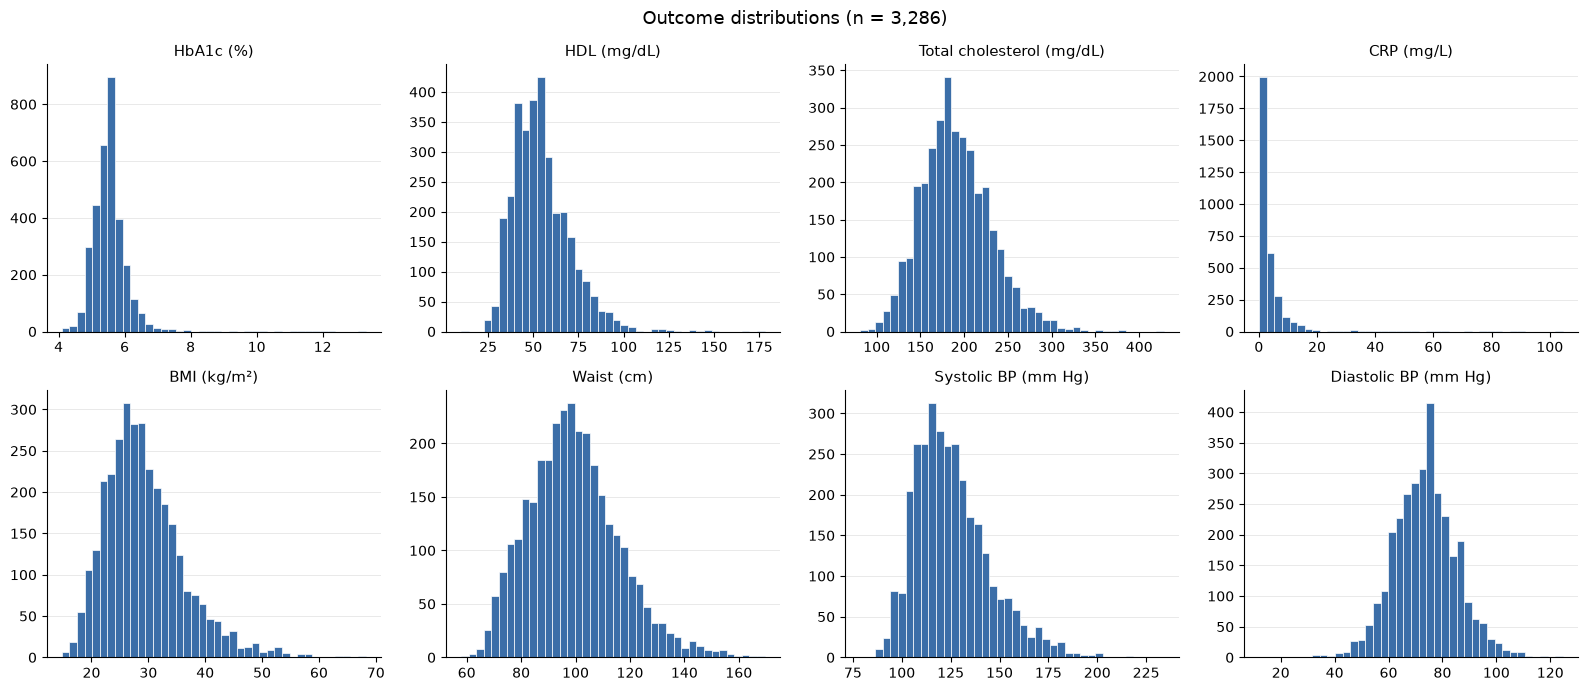

In [151]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, (col, name) in zip(axes.flat, outcomes.items()):
    ax.hist(df[col].dropna(), bins=40, color="#3B6EA8", edgecolor="white", linewidth=0.5)
    ax.set_title(name, fontsize=11)
    ax.grid(axis="y", color="#E5E5E5", linewidth=0.6)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
fig.suptitle("Outcome distributions (n = 3,286)", fontsize=13)
fig.tight_layout()
plt.show()

             skew_raw  skew_log
CRP (mg/L)       6.90      0.33
HDL (mg/dL)      1.33      0.16
BMI (kg/m²)      1.16      0.33
Waist (cm)       0.55      0.07
HbA1c (%)        4.61      2.25

CRP > 10 mg/L: 223


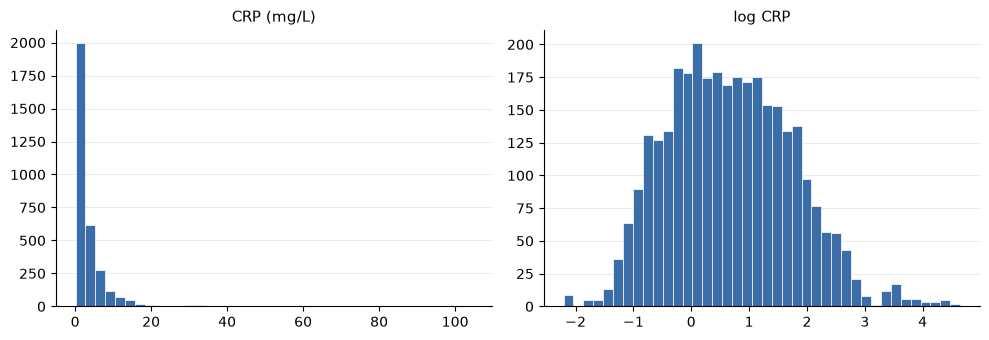

In [152]:
skewed = ["LBXHSCRP", "LBDHDD", "BMXBMI", "BMXWAIST", "LBXGH"]
print(pd.DataFrame({
    "skew_raw": [df[c].skew() for c in skewed],
    "skew_log": [np.log(df[c]).skew() for c in skewed],
}, index=[outcomes[c] for c in skewed]).round(2).to_string())

print("\nCRP > 10 mg/L:", (df["LBXHSCRP"] > 10).sum())

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, data, title in [(axes[0], df["LBXHSCRP"], "CRP (mg/L)"),
                        (axes[1], np.log(df["LBXHSCRP"]), "log CRP")]:
    ax.hist(data.dropna(), bins=40, color="#3B6EA8", edgecolor="white", linewidth=0.5)
    ax.set_title(title, fontsize=11)
    ax.grid(axis="y", color="#E5E5E5", linewidth=0.6)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
fig.tight_layout()
plt.show()

CRP responds well to the log transform, but HbA1c does not. We can sort of understand why visually; CRP had a very skewed right distribution. Thus, the log was able to compress this long tail signficantly. Visually, hbA1c does not spread so far, and its middle portion of its data almost looks normal; the driver of its skew is a very small "tail" that is arguably just a collection of almost disjoint high outliers. We will need to handle these outliers when we perform cross-validation so that they don't bunch into folds and create outlier errors. 

Lets look at candidate outcome correlations:

In [153]:
corr = df[list(outcomes)].corr(method="spearman").round(2)
corr.index = corr.columns = [outcomes[c].split(" (")[0] for c in corr.columns]
print(corr.to_string())

                   HbA1c   HDL  Total cholesterol   CRP   BMI  Waist  Systolic BP  Diastolic BP
HbA1c               1.00 -0.12               0.13  0.21  0.22   0.26         0.31          0.10
HDL                -0.12  1.00               0.15 -0.22 -0.34  -0.37        -0.01         -0.10
Total cholesterol   0.13  0.15               1.00  0.06  0.05   0.06         0.17          0.16
CRP                 0.21 -0.22               0.06  1.00  0.48   0.46         0.13          0.07
BMI                 0.22 -0.34               0.05  0.48  1.00   0.90         0.18          0.16
Waist               0.26 -0.37               0.06  0.46  0.90   1.00         0.26          0.18
Systolic BP         0.31 -0.01               0.17  0.13  0.18   0.26         1.00          0.49
Diastolic BP        0.10 -0.10               0.16  0.07  0.16   0.18         0.49          1.00


BMI and waist are highly correlated, so we should probably keep one; in recent times, waist has become a better indicator of abdominal fat due to the rise of fitness and other bodybuilding strategies that have led to distorted BMI readings. CRP is also moderately correlated. HbA1c strongest correlation is with blood pressure (likely through age); its relatively low correlation with everything may mean predictive power even for the baseline will be very low. If too low, we may need to fall back on a different predictor that is more related to diet (such as waist).

In [154]:
p1k = [c for c in df.columns if c.endswith("_P1K")]

def feature_group(name):
    if name.startswith("FL_"):
        return "Flavonoid"
    if name.startswith(("F_", "V_", "G_", "PF_", "D_")) or name in ("OILS", "SOLID_FATS", "ADD_SUGARS", "A_DRINKS"):
        return "Food group"
    return "Nutrient"

feat = pd.DataFrame({"col": p1k, "feature": [c.removesuffix("_P1K") for c in p1k]})
feat["group"] = feat["feature"].map(feature_group)
feat["share_zero"] = [(df[c] == 0).mean() for c in p1k]
feat["skew"] = [df[c].skew() for c in p1k]
feat["skew_log1p"] = [np.log1p(df[c]).skew() for c in p1k]

summary = feat.groupby("group").agg(
    n_features=("feature", "size"),
    median_share_zero=("share_zero", "median"),
    n_over_half_zero=("share_zero", lambda s: (s > 0.5).sum()),
    median_skew=("skew", "median"),
    median_skew_log1p=("skew_log1p", "median"),
).round(2)
print(summary.to_string())

print("\nMost sparse features:")
print(feat.sort_values("share_zero", ascending=False)
      .head(20)[["feature", "group", "share_zero", "skew", "skew_log1p"]].round(2).to_string(index=False))

            n_features  median_share_zero  n_over_half_zero  median_skew  median_skew_log1p
group                                                                                      
Flavonoid           37               0.36                11         7.37               1.78
Food group          37               0.37                12         2.55               1.51
Nutrient            64               0.00                 3         3.14               0.12

Most sparse features:
        feature      group  share_zero  skew  skew_log1p
       PF_ORGAN Food group        0.98 20.94       13.16
    PF_SEAFD_HI Food group        0.88  7.19        4.47
       D_YOGURT Food group        0.83  5.60        4.25
         PF_SOY Food group        0.83  7.70        5.55
           ATOA   Nutrient        0.82  7.89        3.17
  FL_THEAFLAV3G  Flavonoid        0.78  4.93        2.37
   PF_SEAFD_LOW Food group        0.74  4.80        2.54
       A_DRINKS Food group        0.73  3.60        2.20
    

A couple observations. A lot of zeros in the thematic columns added, and these columns are generally very right skewed. To prevent these skews from driving the fit. Logging 1 plus seems to really help the skew in most cases. Food groups are pretty sparse. It is also clear we will need to standardize given that data is on very different scales (and any regularization will rely on it).

In [155]:
sp = df[p1k].corr(method="spearman")
sp.index = sp.columns = [c.removesuffix("_P1K") for c in p1k]

upper = np.triu(np.ones(sp.shape, dtype=bool), k=1)
pairs = sp.where(upper).stack().reset_index()
pairs.columns = ["feature_a", "feature_b", "rho"]

high = pairs[pairs["rho"].abs() >= 0.8].sort_values("rho", key=abs, ascending=False)
print(f"{len(pairs)} pairs; {len(high)} with |rho| >= 0.8")
print(high.head(40).round(2).to_string(index=False))

partners = pd.concat([high["feature_a"], high["feature_b"]]).value_counts()
print("\nFeatures with the most near-duplicates:")
print(partners.head(15).to_string())

19044 pairs; 84 with |rho| >= 0.8
       feature_a        feature_b  rho
       V_LEGUMES       PF_LEGUMES 1.00
            ALCO         A_DRINKS 1.00
            MFAT             M181 1.00
            PFAT             P182 0.99
 FL_THEAFLAV33DG   FL_THEAFLAV3PG 0.99
    FL_THEARUBIG  FL_THEAFLAV33DG 0.99
      FL_GNSTEIN   FL_TOT_ISOFLAV 0.98
       FL_LUTEOL   FL_TOT_FLAVONE 0.98
    FL_THEARUBIG   FL_THEAFLAV3PG 0.98
       FL_NARING FL_TOT_FLAVANONE 0.97
     FL_THEAFLAV   FL_THEAFLAV3PG 0.97
     FL_THEAFLAV  FL_THEAFLAV33DG 0.97
            FOLA             FDFE 0.97
     FL_THEAFLAV     FL_THEARUBIG 0.96
            S060             S100 0.95
            S080             S100 0.95
FL_TOT_CATECHINS FL_TOT_FLAVAN3OL 0.95
            S040             S060 0.95
            S100             S140 0.94
       FL_QUERCE  FL_TOT_FLAVONOL 0.94
            SFAT             S160 0.93
    FL_PETUNIDIN      FL_MALVIDIN 0.91
   FL_EPICATECG3          FL_EGCG 0.91
            S040             S

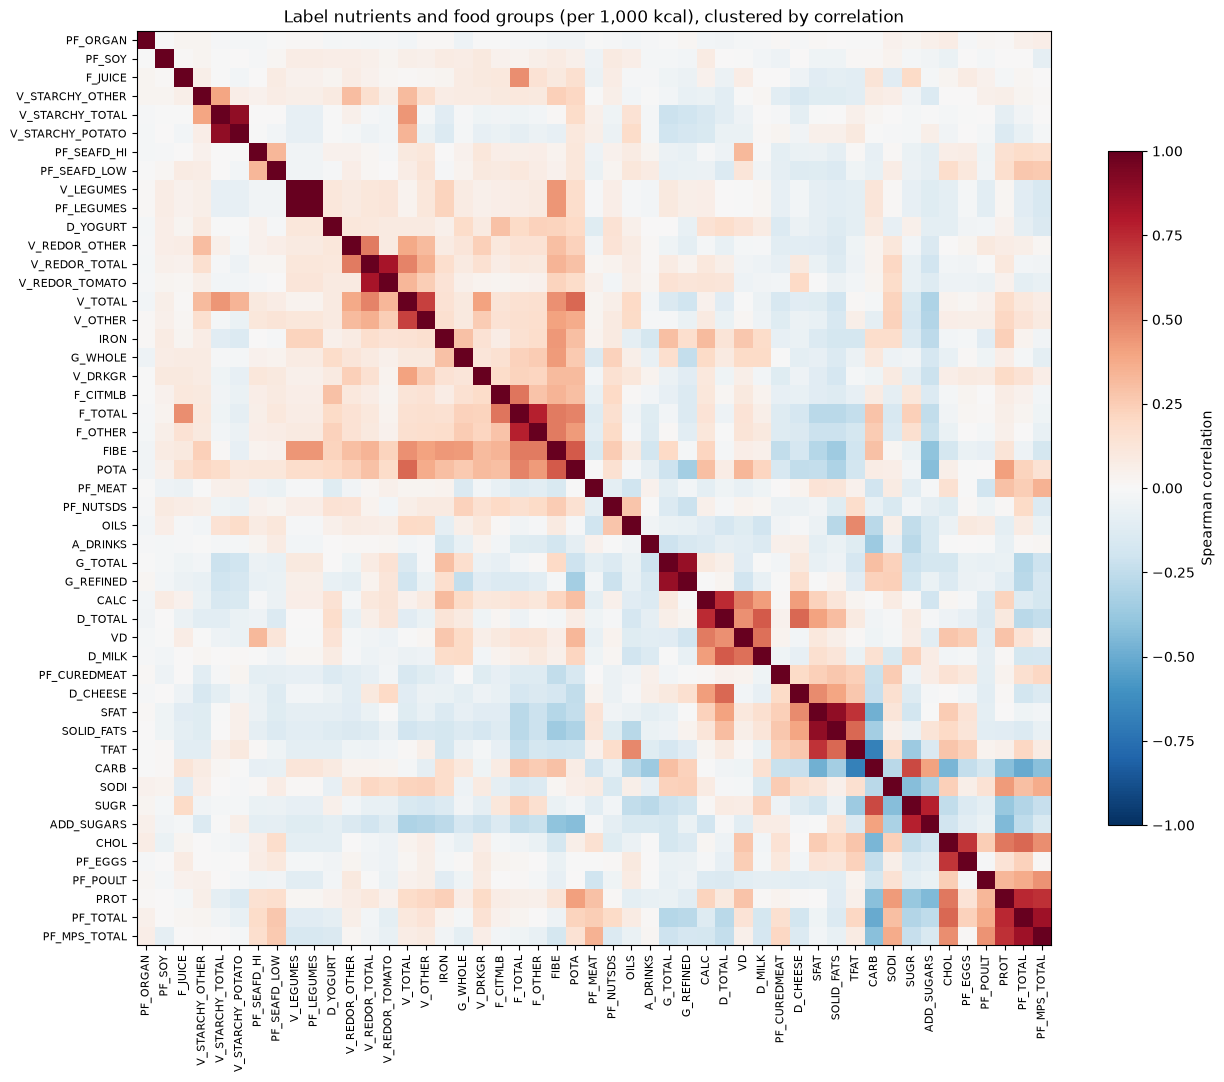

In [156]:
from scipy.cluster.hierarchy import linkage, leaves_list
from scipy.spatial.distance import squareform

label = ["TFAT", "SFAT", "CHOL", "SODI", "CARB", "FIBE", "SUGR", "ADD_SUGARS", "PROT", "VD", "CALC", "IRON", "POTA"]
food_groups = feat.loc[feat["group"] == "Food group", "feature"].tolist()
names = list(dict.fromkeys(label + food_groups))

sub = sp.loc[names, names]
dist = squareform(1 - sub.abs().values, checks=False)
order = leaves_list(linkage(dist, method="average"))
sub = sub.iloc[order, order]

fig, ax = plt.subplots(figsize=(13, 11))
im = ax.imshow(sub.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(sub)))
ax.set_xticklabels(sub.columns, rotation=90, fontsize=8)
ax.set_yticks(range(len(sub)))
ax.set_yticklabels(sub.index, fontsize=8)
fig.colorbar(im, ax=ax, shrink=0.7, label="Spearman correlation")
ax.set_title("Label nutrients and food groups (per 1,000 kcal), clustered by correlation")
fig.tight_layout()
plt.show()

A lot of tiny blocks represent aggregation columns and their individual consitutients. Notice food groups collapse information but often track with a handful of nutrients (think dairy, calcium, saturated fat). In this way, these food labels can smuggle in more with less. Fat, protein, and carbs are negatively correlated, which makes sense since per 1000 kcal. Some features like meat, yogurt, and alcohol are largely uncorrelated with everything.

Generally, these correlation plots also makes it clear that we need to choose between a single representation of certain items (alcohol v. alcoholic drinks, fat types, etc.) that are almost perfectly correlated. In other cases, many of these categories have a choice between subgroups or aggregations, and there is a trade-off for both. Subgroups gives us more granularity, but its costly in terms of restrcited total predictors. We should not have both, though; coefficients get distorted, interpretations (holding x constant) don't work, and selection becomes a bit arbitrary. 

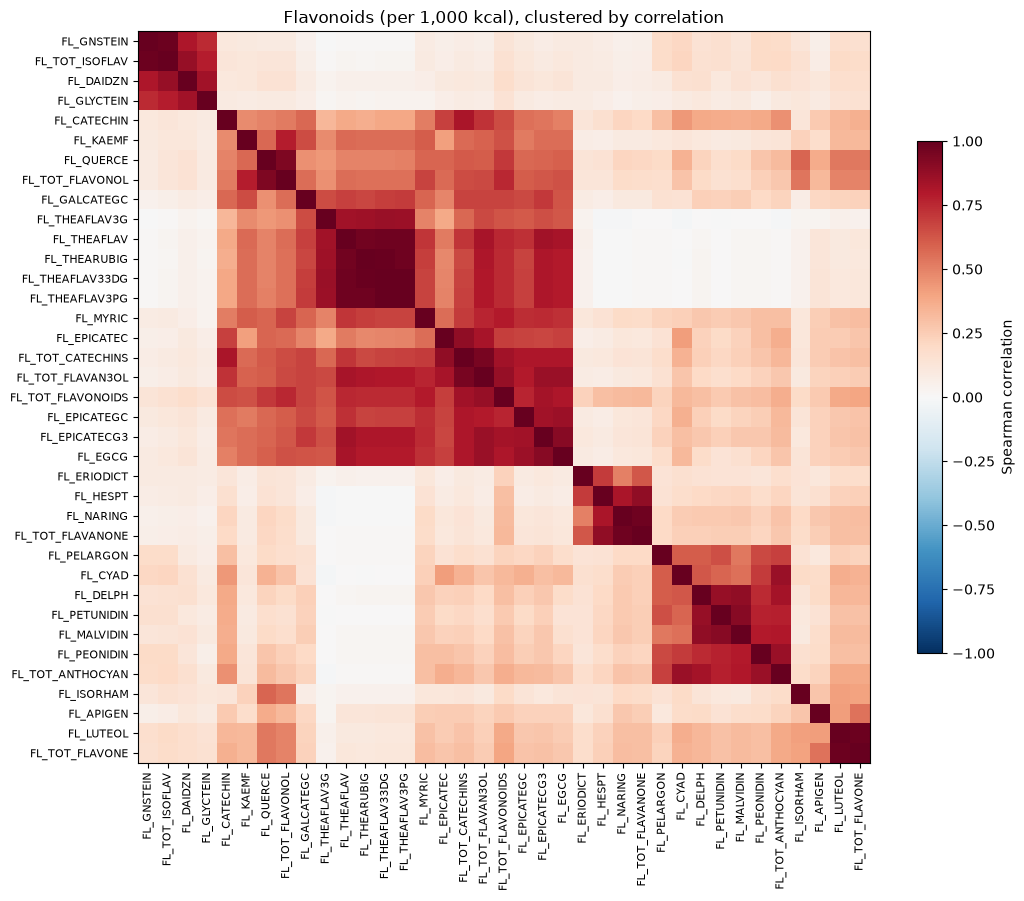

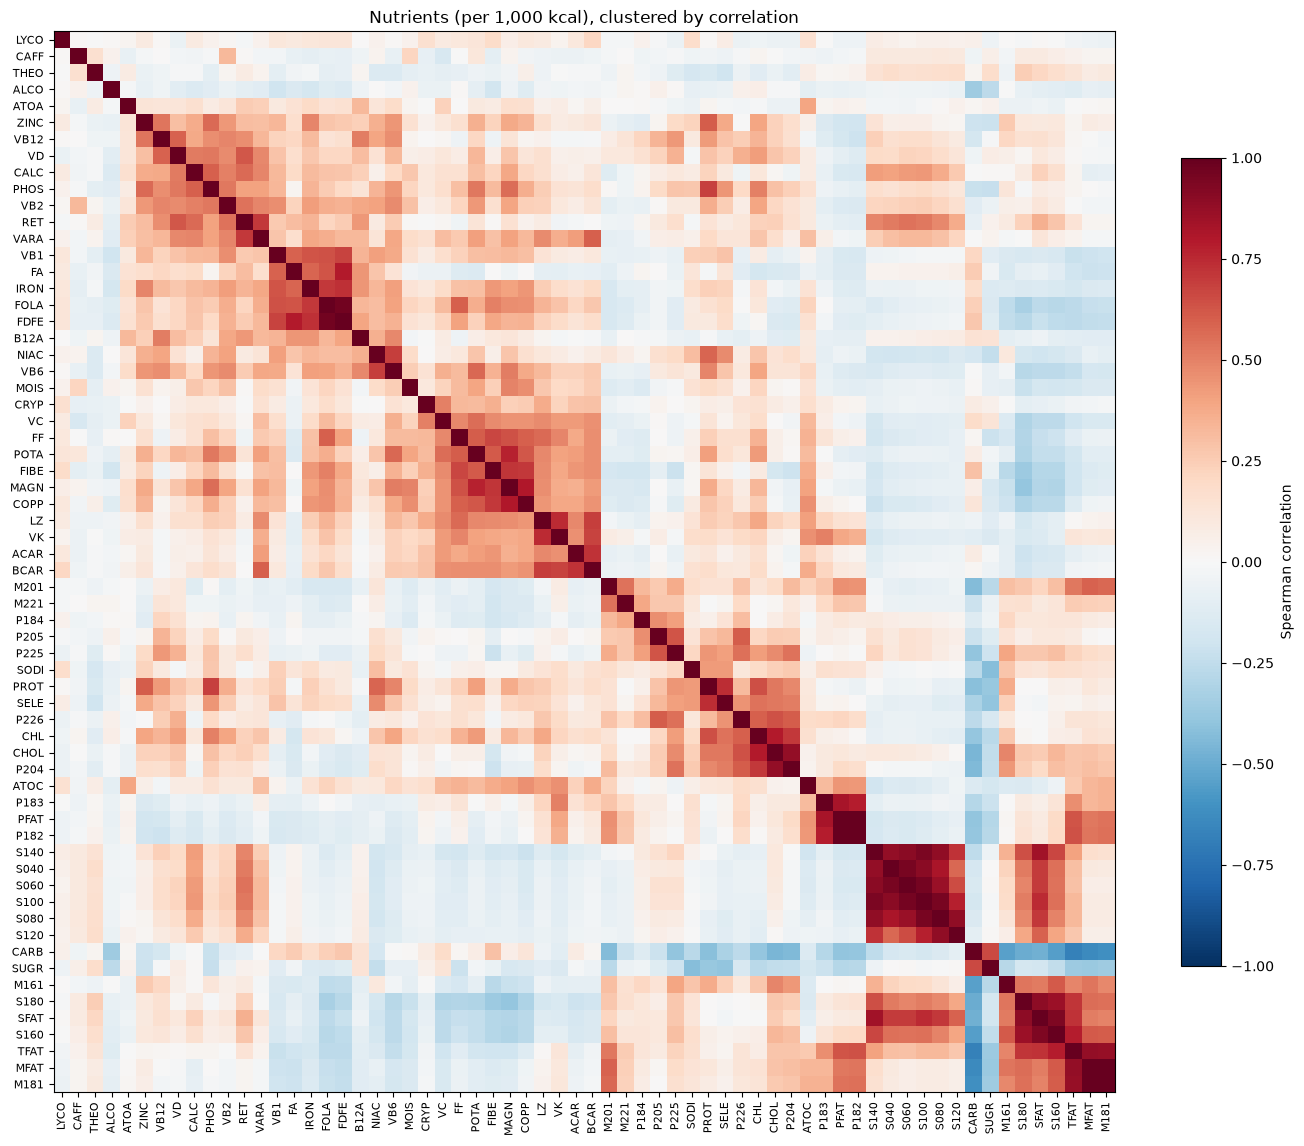

In [157]:
def corr_heatmap(names, title, size=(12, 10)):
    sub = sp.loc[names, names]
    dist = squareform(1 - sub.abs().values, checks=False)
    order = leaves_list(linkage(dist, method="average"))
    sub = sub.iloc[order, order]

    fig, ax = plt.subplots(figsize=size)
    im = ax.imshow(sub.values, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(len(sub)))
    ax.set_xticklabels(sub.columns, rotation=90, fontsize=8)
    ax.set_yticks(range(len(sub)))
    ax.set_yticklabels(sub.index, fontsize=8)
    fig.colorbar(im, ax=ax, shrink=0.7, label="Spearman correlation")
    ax.set_title(title)
    fig.tight_layout()
    plt.show()

flav_names = feat.loc[feat["group"] == "Flavonoid", "feature"].tolist()
nutr_names = feat.loc[feat["group"] == "Nutrient", "feature"].tolist()

corr_heatmap(flav_names, "Flavonoids (per 1,000 kcal), clustered by correlation", size=(11, 9))
corr_heatmap(nutr_names, "Nutrients (per 1,000 kcal), clustered by correlation", size=(14, 12))

The flavanoids show an interesting breakdown, and there is high correlation between certain collections. Roughly, there appears to be five groups: isoflavones (found in soy), flavonols/flavan-3-ols (found in many different foods including tea, cocoa, apples), anthocyanidins (berries, grapes, etc.), and flavones (vegetables and herbs). This suggests grouping into classes.

In the second visual, we see a similar clustering of nutrients based on food groups; you can argue that there are 7-9 different groups here (based on high correlations). As support for the current nutrition label, many of the current nutrients actually cover most of these blocks (sometimes multiple times). 

In [158]:
sp_full = df[p1k].corr(method="spearman")
sp_full.index = sp_full.columns = [c.removesuffix("_P1K") for c in p1k]

groups = {
    "Isoflavones": ["FL_DAIDZN", "FL_GNSTEIN", "FL_GLYCTEIN"],
    "Anthocyanidins": ["FL_CYAD", "FL_PETUNIDIN", "FL_DELPH", "FL_MALVIDIN", "FL_PELARGON", "FL_PEONIDIN"],
    "Flavan-3-ols": ["FL_CATECHIN", "FL_EPICATEGC", "FL_EPICATEC", "FL_EPICATECG3", "FL_EGCG", "FL_THEAFLAV",
                     "FL_THEARUBIG", "FL_THEAFLAV33DG", "FL_THEAFLAV3PG", "FL_THEAFLAV3G", "FL_GALCATEGC"],
    "Flavanones": ["FL_ERIODICT", "FL_HESPT", "FL_NARING"],
    "Flavones": ["FL_APIGEN", "FL_LUTEOL"],
    "Flavonols": ["FL_ISORHAM", "FL_KAEMF", "FL_MYRIC", "FL_QUERCE"],
    "Saturated FAs": ["S040", "S060", "S080", "S100", "S120", "S140", "S160", "S180"],
    "Monounsaturated FAs": ["M161", "M181", "M201", "M221"],
    "Polyunsaturated FAs": ["P182", "P183", "P184", "P204", "P205", "P225", "P226"],
    "Vitamin A": ["RET", "BCAR", "ACAR", "CRYP"],
    "Folate": ["FF", "FA"],
    "Fruit": ["F_CITMLB", "F_OTHER", "F_JUICE"],
    "Vegetables": ["V_DRKGR", "V_REDOR_TOTAL", "V_STARCHY_TOTAL", "V_OTHER"],
    "Grains": ["G_WHOLE", "G_REFINED"],
    "Dairy": ["D_MILK", "D_YOGURT", "D_CHEESE"],
    "Meat/poultry/seafood": ["PF_MEAT", "PF_CUREDMEAT", "PF_ORGAN", "PF_POULT", "PF_SEAFD_HI", "PF_SEAFD_LOW"],
}

def mean_offdiag(cols):
    m = sp_full.loc[cols, cols].values
    return m[~np.eye(len(cols), dtype=bool)].mean()

print(pd.Series({g: mean_offdiag(c) for g, c in groups.items()}).sort_values(ascending=False).round(2).to_string())

Isoflavones             0.80
Saturated FAs           0.71
Anthocyanidins          0.70
Flavan-3-ols            0.69
Flavanones              0.67
Flavonols               0.45
Flavones                0.42
Monounsaturated FAs     0.38
Polyunsaturated FAs     0.30
Vitamin A               0.21
Fruit                   0.18
Vegetables              0.11
Dairy                  -0.02
Meat/poultry/seafood   -0.02
Folate                 -0.13
Grains                 -0.24


Based on these observations, we can reduce our predictor space:

In [159]:
df["OMEGA3_P1K"] = df["P205_P1K"] + df["P226_P1K"]
df["LC_N3_P1K"] = df["P205_P1K"] + df["P225_P1K"] + df["P226_P1K"]
df["LEGUMES_P1K"] = df["V_LEGUMES_P1K"]
df["F_WHOLE_P1K"] = df["F_CITMLB_P1K"] + df["F_OTHER_P1K"]

drop = (
    ["FOLA", "FDFE", "ALCO", "VARA", "TFAT", "MFAT", "PFAT", "CARB"]
    + ["S040", "S060", "S080", "S100", "S120", "S140", "S160", "S180"]
    + ["P205", "P225", "P226"]
    + ["F_TOTAL", "V_TOTAL", "V_REDOR_TOTAL", "V_STARCHY_TOTAL", "G_TOTAL", "PF_TOTAL", "PF_MPS_TOTAL", "D_TOTAL"]
    + ["V_LEGUMES", "PF_LEGUMES", "PF_ORGAN"]
)
flav_keep = (
    ["FL_TOT_ISOFLAV", "FL_TOT_FLAVAN3OL", "FL_TOT_FLAVANONE", "FL_TOT_ANTHOCYAN"]
    + ["FL_ISORHAM", "FL_KAEMF", "FL_MYRIC", "FL_QUERCE"]
    + ["FL_APIGEN", "FL_LUTEOL"]
)

pool = [f for f in feat["feature"]
        if f not in drop and (not f.startswith("FL_") or f in flav_keep)]
pool += ["LEGUMES", "LC_N3"]
pool_cols = [f + "_P1K" for f in pool]

print(len(pool_cols), "candidate features")

83 candidate features


Now, let's take a look at remaining predictors:

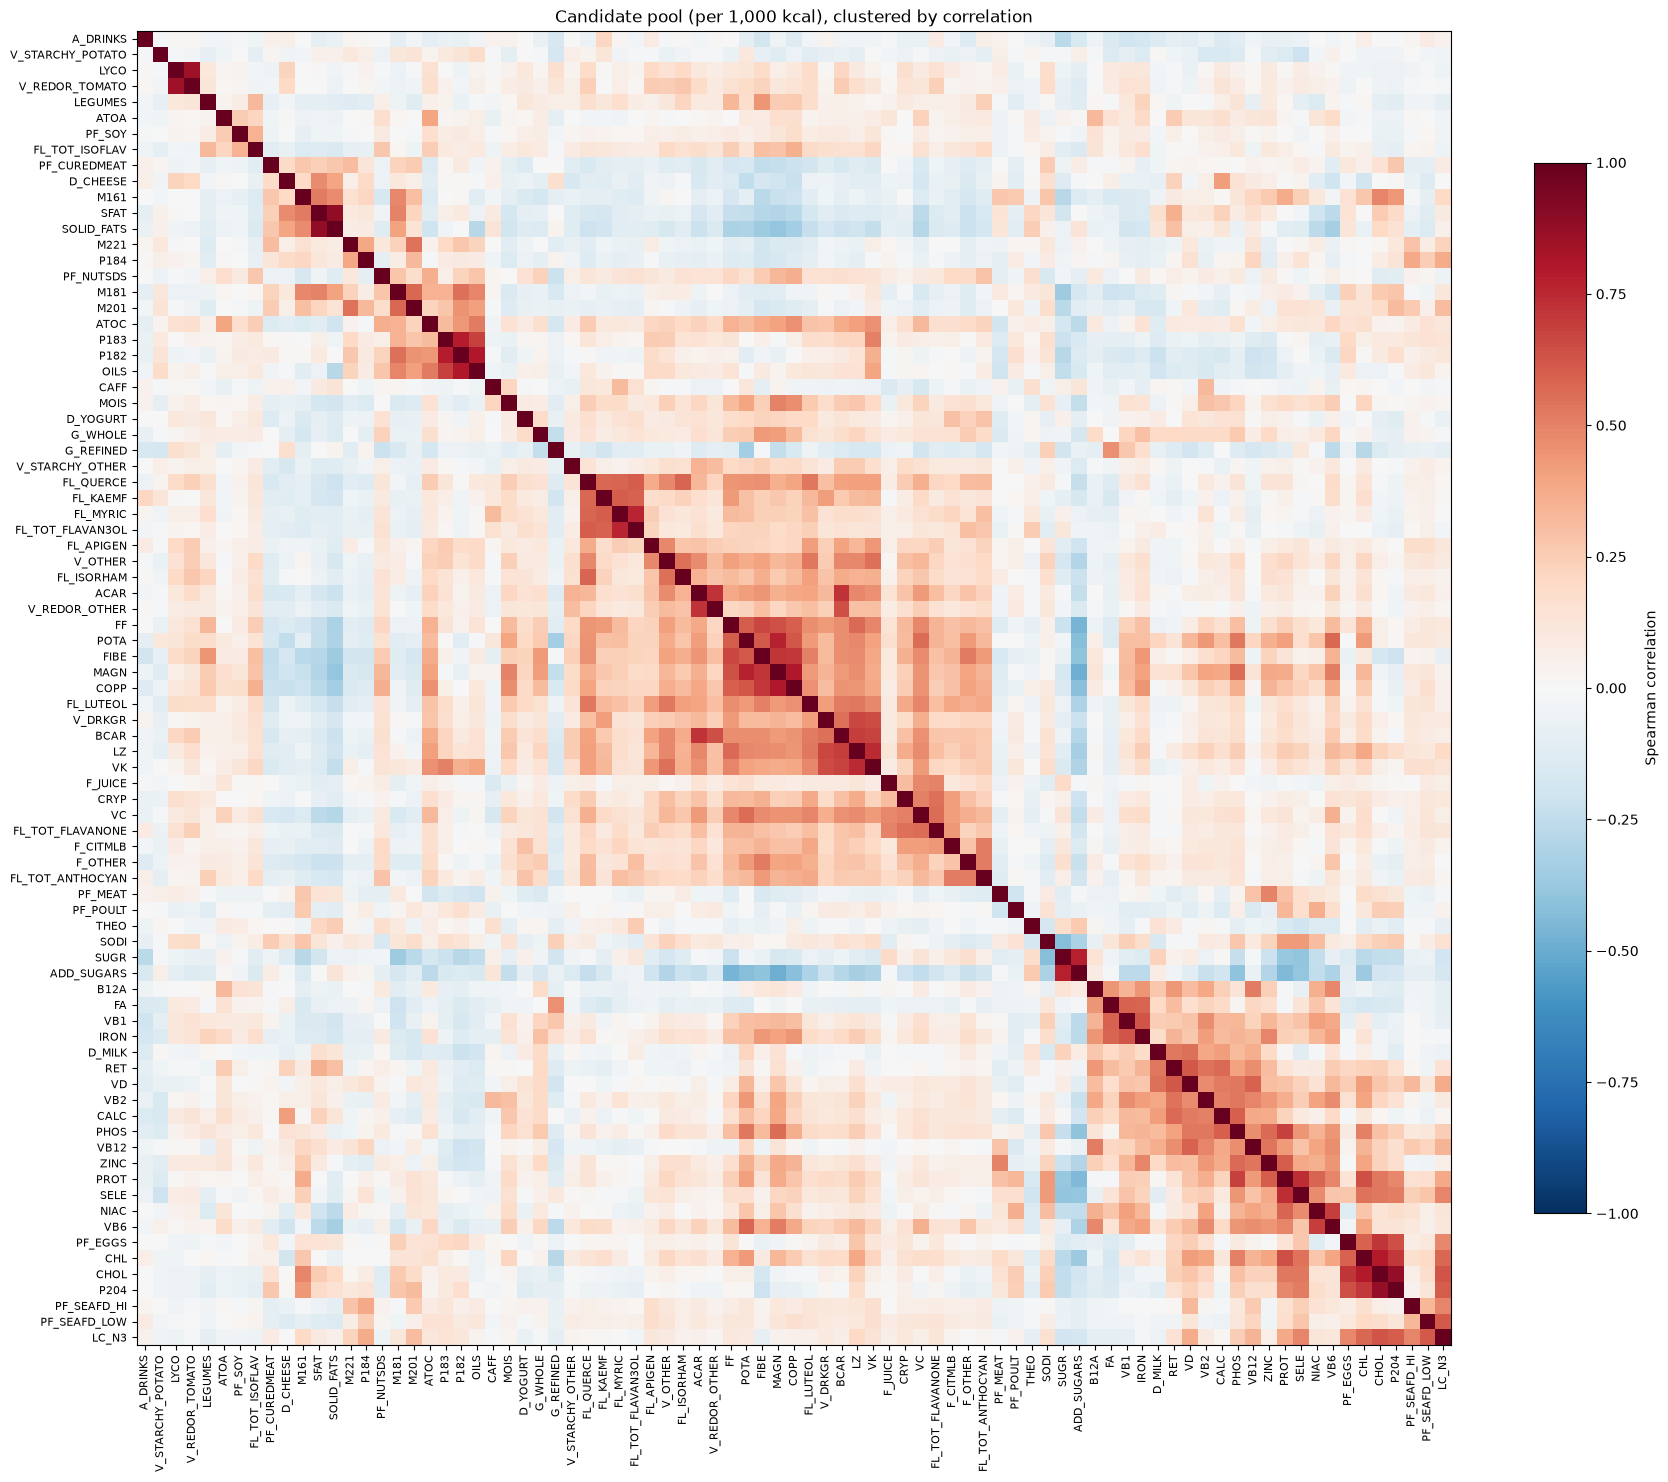

Strongest correlations between features from different groups:
           a                b  rho    group_a    group_b
        SFAT       SOLID_FATS 0.89   Nutrient Food group
        LYCO   V_REDOR_TOMATO 0.85   Nutrient Food group
        P182             OILS 0.80   Nutrient Food group
        SUGR       ADD_SUGARS 0.77   Nutrient Food group
        ACAR    V_REDOR_OTHER 0.72   Nutrient Food group
        CHOL          PF_EGGS 0.72   Nutrient Food group
        P183             OILS 0.68   Nutrient Food group
          LZ          V_DRKGR 0.67   Nutrient Food group
          VK          V_DRKGR 0.65   Nutrient Food group
        P204          PF_EGGS 0.65   Nutrient Food group
        BCAR    V_REDOR_OTHER 0.64   Nutrient Food group
PF_SEAFD_LOW            LC_N3 0.61 Food group   Nutrient
         CHL          PF_EGGS 0.59   Nutrient Food group
          VC FL_TOT_FLAVANONE 0.56   Nutrient  Flavonoid
          VK          V_OTHER 0.55   Nutrient Food group
          VD           D_

In [160]:
sp_pool = df[pool_cols].corr(method="spearman")
sp_pool.index = sp_pool.columns = pool

sp = sp_pool
corr_heatmap(pool, "Candidate pool (per 1,000 kcal), clustered by correlation", size=(18, 16))

def pool_group(f):
    if f.startswith("FL_"):
        return "Flavonoid"
    if f == "LEGUMES":
        return "Food group"
    return feature_group(f)

groups_of = {f: pool_group(f) for f in pool}
up = np.triu(np.ones(sp_pool.shape, dtype=bool), k=1)
cross = sp_pool.where(up).stack().reset_index()
cross.columns = ["a", "b", "rho"]
cross["group_a"] = cross["a"].map(groups_of)
cross["group_b"] = cross["b"].map(groups_of)
cross = cross[cross["group_a"] != cross["group_b"]]

print("Strongest correlations between features from different groups:")
print(cross.reindex(cross["rho"].abs().sort_values(ascending=False).index)
      .head(25).round(2).to_string(index=False))

There are again distinct collections, but most of these appear to align with dietary trends. There is a clear grouping of animal proteins, dairy, fortified foods, fats, yogurt/nuts/whole grains, and a huge plant block at the bottom. Some blue vertical striping also tells interesting stories. Vertical striping of added sugar indicates that people tend to get less of the good stuff (plant block and other phytochemicals); same thing occurs with solid fats. Could be real or could just be a crowding out effect by the 1000 kcal normalization.

In [161]:
pairs_check = [("ADD_SUGARS", "FIBE"), ("ADD_SUGARS", "POTA"), ("SOLID_FATS", "FIBE"), ("SOLID_FATS", "MAGN")]
print(pd.DataFrame({
    "per_1000_kcal": [df[f"{a}_P1K"].corr(df[f"{b}_P1K"], method="spearman") for a, b in pairs_check],
    "absolute": [df[a].corr(df[b], method="spearman") for a, b in pairs_check],
}, index=[f"{a} vs {b}" for a, b in pairs_check]).round(2).to_string())

                    per_1000_kcal  absolute
ADD_SUGARS vs FIBE          -0.40     -0.03
ADD_SUGARS vs POTA          -0.43      0.10
SOLID_FATS vs FIBE          -0.36      0.10
SOLID_FATS vs MAGN          -0.38      0.21


Claude: Added sugars and solid fats correlate negatively with fiber, potassium and
  magnesium per 1,000 kcal (ρ ≈ −0.4) but not in absolute terms (ρ ≈ −0.03 to +0.21), consistent with displacement within a fixed energy budget. Carbohydrate vs fat (ρ ≈ −0.8) is the extreme case.


We should also consider VIF, which will allows us to catch dependencies that are not pairwise.

In [162]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

Xd = np.log1p(df[pool_cols]).dropna()
Xd.columns = pool
Xc = np.column_stack([np.ones(len(Xd)), Xd.values])

vif_diet = pd.Series([variance_inflation_factor(Xc, i + 1) for i in range(Xd.shape[1])], index=Xd.columns)
print(vif_diet.sort_values(ascending=False).head(25).round(1).to_string())
print("\nFeatures with VIF > 10:", (vif_diet > 10).sum(), "of", len(vif_diet))

PROT           13.7
SUGR           12.3
CHL            10.7
ADD_SUGARS     10.4
MAGN            9.7
POTA            9.3
SFAT            8.5
SOLID_FATS      8.3
FIBE            8.3
P182            7.2
CHOL            7.2
NIAC            7.1
VK              7.0
LC_N3           6.6
PF_SEAFD_HI     6.6
M181            6.6
VB12            6.5
VD              6.1
P204            6.1
VB6             5.9
OILS            5.7
PHOS            5.6
B12A            5.5
PF_EGGS         5.4
CALC            5.3

Features with VIF > 10: 4 of 83


As expected, the densities are relatively high, and we will expect lasso to drop one. We should also consider breaking sugar into added sugar and natural sugar so that the two predictors are less ocrrelated. Many of the remaining high VIFs are resulting from natural cooccurences in foods (eggs track cholesterol, choline). Note these drops are for our eventual model.

In [163]:
Xs = Xd.drop(columns=["SUGR"]).assign(NATURAL_SUGR=np.log1p(
    (df.loc[Xd.index, "SUGR_P1K"] - 4.2 * df.loc[Xd.index, "ADD_SUGARS_P1K"]).clip(lower=0)))
Xsc = np.column_stack([np.ones(len(Xs)), Xs.values])

vif_s = pd.Series([variance_inflation_factor(Xsc, i + 1) for i in range(Xs.shape[1])], index=Xs.columns)
print(vif_s.sort_values(ascending=False).head(15).round(1).to_string())
print("\nFeatures with VIF > 10:", (vif_s > 10).sum(), "of", len(vif_s))

PROT            13.5
CHL             10.7
POTA             9.7
MAGN             9.7
SFAT             8.6
SOLID_FATS       8.3
FIBE             8.3
NATURAL_SUGR     8.2
P182             7.2
CHOL             7.1
NIAC             7.1
VK               7.0
LC_N3            6.6
PF_SEAFD_HI      6.6
M181             6.5

Features with VIF > 10: 2 of 83


In [164]:
df["F_WHOLE_P1K"] = df["F_CITMLB_P1K"] + df["F_OTHER_P1K"]

heuristic = ["FIBE", "G_WHOLE", "G_REFINED", "ADD_SUGARS", "F_WHOLE", "V_DRKGR", "LEGUMES",
             "PF_NUTSDS", "PF_MEAT", "PF_CUREDMEAT", "D_YOGURT", "OMEGA3", "FL_TOT_ANTHOCYAN"]
heuristic_cols = [f + "_P1K" for f in heuristic]

y = df["LBXGH"]
cand = list(dict.fromkeys(pool_cols + ["F_WHOLE_P1K"]))
X = np.log1p(df[cand])

ctrl6 = pd.get_dummies(df[["RIAGENDR"]].astype("category"), drop_first=True, dtype=float).assign(AGE=df["RIDAGEYR"])
resid = lambda v: v - LinearRegression().fit(ctrl6, v).predict(ctrl6)

y_r = resid(y)
rows = []
for c in cand:
    rows.append({
        "feature": c.removesuffix("_P1K"),
        "rho_raw": X[c].corr(y, method="spearman"),
        "rho_adj_age_sex": pd.Series(resid(X[c])).corr(pd.Series(y_r), method="spearman"),
    })
assoc = pd.DataFrame(rows).set_index("feature")
assoc["in_label"] = assoc.index.isin(["SFAT", "CHOL", "SODI", "CARB", "FIBE", "SUGR", "ADD_SUGARS",
                                      "PROT", "VD", "CALC", "IRON", "POTA"])
assoc["in_heuristic"] = assoc.index.isin(heuristic)

print(assoc.reindex(assoc["rho_adj_age_sex"].abs().sort_values(ascending=False).index)
      .head(20).round(3).to_string())

                  rho_raw  rho_adj_age_sex  in_label  in_heuristic
feature                                                           
A_DRINKS           -0.140           -0.105     False         False
G_REFINED           0.016            0.094     False          True
CAFF               -0.001           -0.075     False         False
VB2                -0.021           -0.071     False         False
RET                -0.004           -0.049     False         False
P183                0.062            0.044     False         False
FIBE                0.088            0.042      True          True
POTA                0.052           -0.041      True         False
CRYP                0.065            0.038     False         False
FL_TOT_ANTHOCYAN    0.018           -0.037     False          True
FL_LUTEOL           0.037            0.035     False         False
M201                0.034            0.034     False         False
D_CHEESE           -0.107           -0.034     False         F

People: 3286, features: 83
Variance explained by first 10 components: [14.7  8.5  6.5  4.6  4.1  4.   3.4  3.1  2.6  2.5]
Cumulative: [14.7 23.2 29.7 34.3 38.4 42.4 45.8 48.9 51.5 54. ]


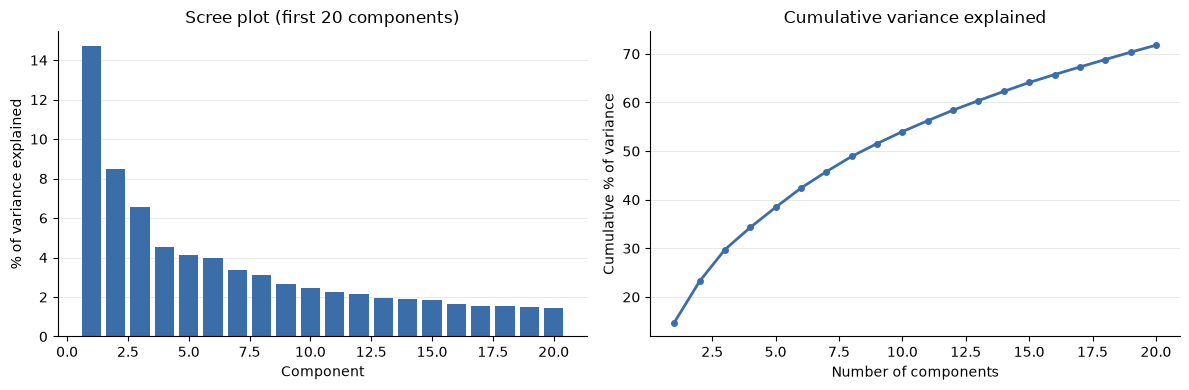

In [165]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

Xp = np.log1p(df[pool_cols]).dropna()
Xp.columns = pool
Z = StandardScaler().fit_transform(Xp)

pca = PCA().fit(Z)
var = pca.explained_variance_ratio_

print(f"People: {len(Xp)}, features: {Xp.shape[1]}")
print("Variance explained by first 10 components:", (var[:10] * 100).round(1))
print("Cumulative:", (np.cumsum(var)[:10] * 100).round(1))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
k = np.arange(1, 21)
axes[0].bar(k, var[:20] * 100, color="#3B6EA8")
axes[0].set_xlabel("Component")
axes[0].set_ylabel("% of variance explained")
axes[0].set_title("Scree plot (first 20 components)")
axes[1].plot(k, np.cumsum(var)[:20] * 100, color="#3B6EA8", linewidth=2, marker="o", markersize=4)
axes[1].set_xlabel("Number of components")
axes[1].set_ylabel("Cumulative % of variance")
axes[1].set_title("Cumulative variance explained")
for ax in axes:
    ax.grid(axis="y", color="#E5E5E5", linewidth=0.6)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
fig.tight_layout()
plt.show()

In [166]:
loadings = pd.DataFrame(pca.components_[:4].T, index=pool, columns=["PC1", "PC2", "PC3", "PC4"])

for pc in loadings.columns:
    s = loadings[pc].sort_values()
    print(f"\n=== {pc} ({var[int(pc[2:]) - 1] * 100:.1f}% of variance) ===")
    print("Most positive:", ", ".join(f"{f} ({v:.2f})" for f, v in s[::-1].head(8).items()))
    print("Most negative:", ", ".join(f"{f} ({v:.2f})" for f, v in s.head(8).items()))


=== PC1 (14.7% of variance) ===
Most positive: MAGN (0.24), POTA (0.23), FF (0.21), FIBE (0.20), LZ (0.20), COPP (0.20), BCAR (0.19), VK (0.18)
Most negative: ADD_SUGARS (-0.16), SOLID_FATS (-0.11), G_REFINED (-0.07), SFAT (-0.07), SUGR (-0.06), D_CHEESE (-0.05), PF_CUREDMEAT (-0.04), A_DRINKS (-0.04)

=== PC2 (8.5% of variance) ===
Most positive: CHOL (0.24), VB12 (0.24), PROT (0.23), P204 (0.22), SELE (0.21), CHL (0.20), VD (0.20), M161 (0.20)
Most negative: FL_QUERCE (-0.13), FIBE (-0.13), FL_KAEMF (-0.12), FL_LUTEOL (-0.12), SUGR (-0.12), FL_TOT_FLAVAN3OL (-0.11), FL_MYRIC (-0.10), F_OTHER (-0.10)

=== PC3 (6.5% of variance) ===
Most positive: P182 (0.27), M181 (0.26), P183 (0.23), OILS (0.22), M201 (0.20), P204 (0.19), CHOL (0.18), M161 (0.16)
Most negative: B12A (-0.23), D_MILK (-0.21), IRON (-0.19), VB1 (-0.19), SUGR (-0.18), FA (-0.18), VB2 (-0.16), CALC (-0.15)

=== PC4 (4.6% of variance) ===
Most positive: LC_N3 (0.28), PF_SEAFD_HI (0.24), P184 (0.22), PF_SEAFD_LOW (0.15), C